# 23CSE301 Machine Learning — Capstone Project: Review 2
## Notebook 2 of 3 · Classification Track (Part A + Part B)
**Project**: Food Delivery Duration Prediction & Service Delay Classification Pipeline
**Dataset**: Food Delivery Logistics Dataset (`train.csv`, 45,593 orders)
**Task**: Predict whether an order breaches the 25-minute delivery SLA (`Is_Delayed = 1`).

| Review 2 rubric item | Where it is covered |
|---|---|
| **A1** All 5 Part-B algorithms trained on the same data as Part A | Section 4 |
| **A2** Single table comparing all 10 classifiers (Accuracy, Precision, Recall, F1, ROC-AUC) | Section 5 |
| **A3** Hyperparameter tuning, final model selection, documented improvement, best-model write-up | Sections 6–8 |
| **C1** Clean, modular, commented code that runs top to bottom | Whole notebook |

The other two notebooks are `regression.ipynb` (Review 1 regression track) and `clustering.ipynb` (Review 2 clustering track).

---
### 0. Environment setup
All libraries are imported once here. `random_state=42` is used everywhere so the results can be reproduced.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time, warnings, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Part A classifiers (Review 1)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
# Part B classifiers (Review 2)
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, BaggingClassifier)
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
print('Libraries loaded.')

Libraries loaded.


### 1. Data preparation (same pipeline as Review 1)
The cleaning and feature-engineering steps from Review 1 are wrapped into reusable functions so that **all three notebooks use exactly the same data**. The functions:
- extract the numeric target from `Time_taken(min)` and create `Is_Delayed` (1 if delivery took more than 25 minutes),
- turn hidden `'NaN'` text tokens into real missing values and cast numeric columns,
- cap impossible ratings (> 5) and replace invalid (0, 0) coordinates with the median distance,
- engineer `distance_km`, `prep_time_min`, `order_hour`, `is_rush_hour`, `is_weekend` and `Festival_binary`.

In [2]:
# ---------------------------------------------------------------------------
# Shared data-preparation functions (identical across regression, classification
# and clustering notebooks so every track uses exactly the same cleaned data).
# ---------------------------------------------------------------------------
import os

RANDOM_STATE = 42
DATA_CANDIDATES = ['train.csv', 'data/train.csv', '../data/train.csv']


def load_raw_data():
    """Load train.csv from the notebook folder or the repo's data/ folder."""
    for path in DATA_CANDIDATES:
        if os.path.exists(path):
            return pd.read_csv(path)
    raise FileNotFoundError(f'train.csv not found in any of {DATA_CANDIDATES}')


def haversine_dist(lon1, lat1, lon2, lat2):
    """Vectorised great-circle distance in km between two sets of coordinates."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def clean_and_engineer(df_raw, verbose=True):
    """Review 1 cleaning + feature-engineering pipeline, wrapped as one function."""
    df = df_raw.copy()

    # 1. Targets: numeric delivery time (regression) and SLA-breach flag (classification)
    df['Time_taken'] = df['Time_taken(min)'].astype(str).str.extract(r'(\d+)')[0].astype(float)
    df['Is_Delayed'] = (df['Time_taken'] > 25.0).astype(int)

    # 2. Strip whitespace and turn hidden 'NaN' string tokens into real missing values
    text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip().replace({'NaN': np.nan, 'nan': np.nan, '': np.nan})
    df['Weatherconditions'] = (df['Weatherconditions'].str.replace('conditions ', '', regex=False)
                               .replace({'NaN': np.nan, 'nan': np.nan}))

    # 3. Numeric casting and rating outliers (ratings > 5 are data-entry errors)
    for col in ['Delivery_person_Age', 'Delivery_person_Ratings', 'multiple_deliveries']:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    n_rating_outliers = int((df['Delivery_person_Ratings'] > 5.0).sum())
    df.loc[df['Delivery_person_Ratings'] > 5.0, 'Delivery_person_Ratings'] = 5.0

    # 4. Haversine distance; invalid (near-zero) coordinates replaced by the median distance
    lat1, lon1 = df['Restaurant_latitude'].abs(), df['Restaurant_longitude'].abs()
    lat2, lon2 = df['Delivery_location_latitude'].abs(), df['Delivery_location_longitude'].abs()
    df['distance_km'] = haversine_dist(lon1, lat1, lon2, lat2)
    valid = (lat1 > 1.0) & (lon1 > 1.0) & (lat2 > 1.0) & (lon2 > 1.0)
    df.loc[~valid, 'distance_km'] = df.loc[valid, 'distance_km'].median()

    # 5. Kitchen preparation time (order placed -> order picked up), overnight wrap fixed
    t_order = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Orderd'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    t_picked = pd.to_datetime(df['Order_Date'] + ' ' + df['Time_Order_picked'], format='%d-%m-%Y %H:%M:%S', errors='coerce')
    prep = (t_picked - t_order).dt.total_seconds() / 60.0
    prep = prep.where(prep >= 0, prep + 1440.0)
    df['prep_time_min'] = prep.fillna(prep.median())

    # 6. Temporal features
    df['order_hour'] = t_order.dt.hour.fillna(17)
    df['is_rush_hour'] = df['order_hour'].isin([12, 13, 14, 19, 20, 21]).astype(int)
    order_date = pd.to_datetime(df['Order_Date'], format='%d-%m-%Y', errors='coerce')
    df['day_of_week'] = order_date.dt.dayofweek.fillna(2)
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)
    df['Festival_binary'] = (df['Festival'] == 'Yes').astype(int)

    # 7. Ordinal traffic level (used by the clustering track)
    df['traffic_level'] = df['Road_traffic_density'].map({'Low': 0, 'Medium': 1, 'High': 2, 'Jam': 3})

    if verbose:
        print(f'Rows: {len(df):,} | rating outliers capped: {n_rating_outliers} | '
              f'coordinate anomalies fixed: {int((~valid).sum())} | duplicate IDs: {int(df["ID"].duplicated().sum())}')
    return df


NUMERICAL_COLS = ['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'prep_time_min',
                  'order_hour', 'Vehicle_condition', 'multiple_deliveries', 'Festival_binary',
                  'is_rush_hour', 'is_weekend']
CATEGORICAL_COLS = ['Weatherconditions', 'Road_traffic_density', 'City', 'Type_of_vehicle']


def build_preprocessor():
    """Median-impute + scale numerics; mode-impute + one-hot categoricals. Fit on TRAIN only."""
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))])
    return ColumnTransformer([('num', num_pipe, NUMERICAL_COLS), ('cat', cat_pipe, CATEGORICAL_COLS)])


def get_feature_names(preprocessor):
    cat_names = preprocessor.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(CATEGORICAL_COLS)
    return NUMERICAL_COLS + list(cat_names)

df = clean_and_engineer(load_raw_data())

Rows: 45,593 | rating outliers capped: 53 | coordinate anomalies fixed: 3640 | duplicate IDs: 0


#### 1.1 Class balance check
Because the 25-minute threshold sits close to the median delivery time, the two classes should be roughly balanced. We check this before choosing metrics.

,Orders,Share (%)
Is_Delayed,,
On time (0),22749,49.8958
Delayed (1),22844,50.1042


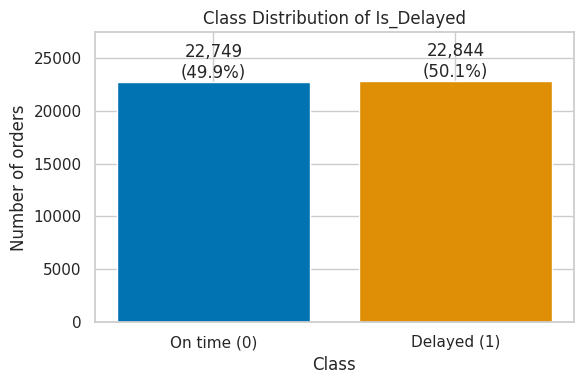

In [3]:
class_counts = df['Is_Delayed'].value_counts().sort_index()
class_share = df['Is_Delayed'].value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({'Orders': class_counts, 'Share (%)': class_share},
                     index=pd.Index([0, 1], name='Is_Delayed')).rename(index={0: 'On time (0)', 1: 'Delayed (1)'}))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['On time (0)', 'Delayed (1)'], class_counts.values, color=sns.color_palette('colorblind')[:2])
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f'{v:,}\n({class_share.values[i]:.1f}%)', ha='center', va='bottom')
ax.set_title('Class Distribution of Is_Delayed')
ax.set_xlabel('Class')
ax.set_ylabel('Number of orders')
ax.set_ylim(0, class_counts.max() * 1.2)
plt.tight_layout()
plt.show()

#### Observation 1.1: Class balance
- The target is almost perfectly balanced: **22,749 on-time (49.9%)** and **22,844 delayed (50.1%)** orders.
- This means **accuracy is a fair headline metric** here. A model that always predicts one class would only score about 50%.
- We still report weighted Precision, Recall and F1 because they show whether a model favours one class over the other. ROC-AUC shows ranking quality regardless of the 0.5 threshold.

#### 1.2 Leak-free, stratified 80:20 split
The split uses the **same seed and stratification as Review 1**, so the Part A numbers are reproduced exactly and all ten classifiers are compared on the same 9,119 test orders. The preprocessor is fitted on the training set only and then applied to the test set.

In [4]:
X = df[NUMERICAL_COLS + CATEGORICAL_COLS]
y = df['Is_Delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

preprocessor = build_preprocessor()
X_train_p = preprocessor.fit_transform(X_train)   # fit on TRAIN only
X_test_p = preprocessor.transform(X_test)         # apply to TEST
feature_names = get_feature_names(preprocessor)

# Fixed 8,000-row subset of the training set, used where a model is too slow on all 36k rows (SVC)
sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train_p), 8000, replace=False)

print(f'Train: {X_train_p.shape} | Test: {X_test_p.shape}')
print(f'Delayed share  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}')

Train: (36474, 23) | Test: (9119, 23)
Delayed share  train: 0.501 | test: 0.501


### 2. Evaluation helper
One function trains a model, predicts on the shared test set and stores all mandatory metrics (Accuracy, weighted Precision, Recall and F1, ROC-AUC, confusion matrix). This keeps every one of the ten models evaluated in exactly the same way.

In [5]:
results, predictions, scores, fitted_models = {}, {}, {}, {}


def evaluate_classifier(name, model, part, X_tr=None, y_tr=None):
    """Fit `model`, score it on the shared test split and store the results."""
    X_tr = X_train_p if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    start = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start

    y_pred = model.predict(X_test_p)
    # Probability of class 1 for ROC-AUC (decision_function for models without predict_proba)
    y_score = model.predict_proba(X_test_p)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_p)

    results[name] = {
        'Part': part,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (W)': precision_score(y_test, y_pred, average='weighted'),
        'Recall (W)': recall_score(y_test, y_pred, average='weighted'),
        'F1-Score (W)': f1_score(y_test, y_pred, average='weighted'),
        'ROC-AUC': roc_auc_score(y_test, y_score),
        'Train time (s)': train_time,
    }
    predictions[name], scores[name], fitted_models[name] = y_pred, y_score, model
    r = results[name]
    print(f"[{name:<28}] Acc {r['Accuracy']:.4f} | F1 {r['F1-Score (W)']:.4f} | "
          f"ROC-AUC {r['ROC-AUC']:.4f} | {train_time:.1f}s")
    return model

---
### 3. Classification Part A — recap of Review 1 (5 algorithms)
These five models use the same settings as Review 1. They are retrained here only so that Part A and Part B can be compared in one table on the same split (rubric A2).

In [6]:
evaluate_classifier('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), 'A')
evaluate_classifier('K-Nearest Neighbors', KNeighborsClassifier(n_neighbors=9, weights='distance', n_jobs=-1), 'A')
evaluate_classifier('Gaussian Naive Bayes', GaussianNB(), 'A')
evaluate_classifier('Decision Tree', DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE), 'A')
# SVC scales roughly quadratically with rows, so (as in Review 1) it is trained on the fixed 8,000-row subset
evaluate_classifier('Support Vector Classifier', SVC(C=2.0, kernel='rbf', random_state=RANDOM_STATE), 'A',
                    X_tr=X_train_p[sub_idx], y_tr=y_train.iloc[sub_idx]);

[Logistic Regression         ] Acc 0.7857 | F1 0.7857 | ROC-AUC 0.8689 | 0.4s


[K-Nearest Neighbors         ] Acc 0.7986 | F1 0.7985 | ROC-AUC 0.8811 | 0.0s
[Gaussian Naive Bayes        ] Acc 0.5251 | F1 0.3885 | ROC-AUC 0.8486 | 0.0s
[Decision Tree               ] Acc 0.8104 | F1 0.8090 | ROC-AUC 0.8998 | 0.1s


[Support Vector Classifier   ] Acc 0.8186 | F1 0.8185 | ROC-AUC 0.9016 | 1.4s


---
### 4. Classification Part B — Review 2 (5 algorithms)  [Rubric A1]
All five Part B models are ensemble or neural-network methods. They are first trained with **sensible baseline settings**; their required hyperparameters are tuned in Section 6.

| # | Algorithm | Idea | Baseline setting |
|---|---|---|---|
| 6 | Random Forest | Bagging of decorrelated trees (random feature subsets) | 100 trees |
| 7 | AdaBoost | Sequentially re-weights misclassified orders; combines weak learners | 50 stumps, learning rate 1.0 |
| 8 | Gradient Boosting | Each new tree fits the errors (gradient) of the current ensemble | 100 trees, depth 3, learning rate 0.1 |
| 9 | Bagging | Bootstrap samples, one full decision tree per sample, majority vote | 50 decision trees |
| 10 | MLP (neural network) | Fully connected network trained by back-propagation | one hidden layer of 100 ReLU units |

In [7]:
# 6. Random Forest
evaluate_classifier('Random Forest', RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), 'B')

# 7. AdaBoost (default weak learner = depth-1 decision stump)
evaluate_classifier('AdaBoost', AdaBoostClassifier(
    n_estimators=50, learning_rate=1.0, random_state=RANDOM_STATE), 'B')

# 8. Gradient Boosting (sklearn GBM)
evaluate_classifier('Gradient Boosting', GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=RANDOM_STATE), 'B')

# 9. Bagging with a Decision Tree as base estimator (as required by the guidelines)
evaluate_classifier('Bagging (Decision Tree)', BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1), 'B')

# 10. MLP neural network (early stopping holds out 10% of train to stop before overfitting)
evaluate_classifier('MLP Neural Network', MLPClassifier(
    hidden_layer_sizes=(100,), activation='relu', max_iter=300,
    early_stopping=True, random_state=RANDOM_STATE), 'B');

[Random Forest               ] Acc 0.8275 | F1 0.8274 | ROC-AUC 0.9196 | 1.3s


[AdaBoost                    ] Acc 0.7955 | F1 0.7954 | ROC-AUC 0.8829 | 0.8s


[Gradient Boosting           ] Acc 0.8329 | F1 0.8326 | ROC-AUC 0.9151 | 3.7s


[Bagging (Decision Tree)     ] Acc 0.8257 | F1 0.8257 | ROC-AUC 0.9190 | 3.4s


[MLP Neural Network          ] Acc 0.8306 | F1 0.8302 | ROC-AUC 0.9195 | 4.1s


#### 4.1 Random Forest feature importance
The guidelines ask for Random Forest feature importance. Impurity-based importance shows which features the forest used most often to split the orders.

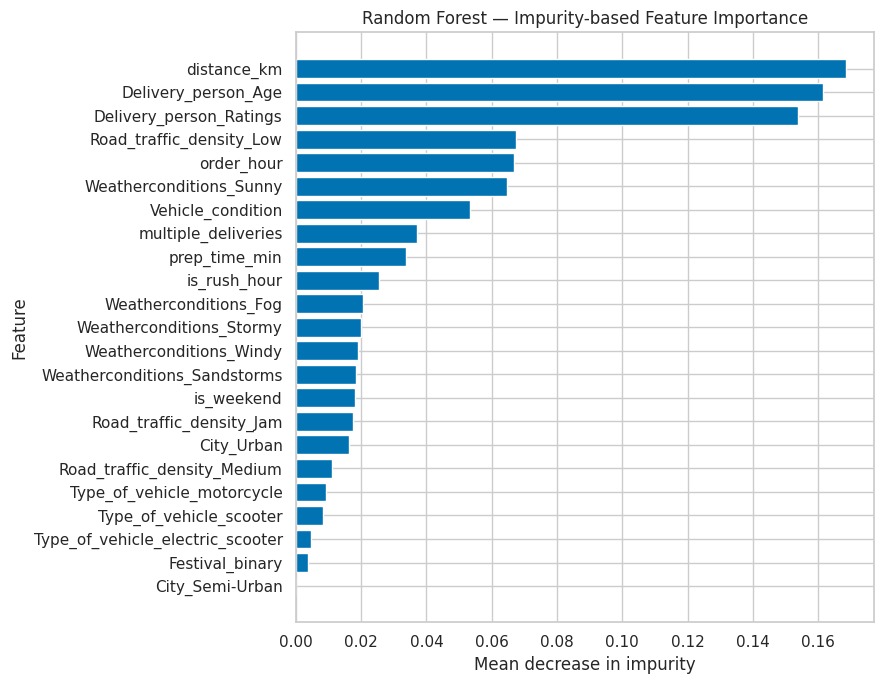

In [8]:
rf_imp = pd.Series(fitted_models['Random Forest'].feature_importances_, index=feature_names).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(rf_imp.index, rf_imp.values, color=sns.color_palette('colorblind')[0])
ax.set_title('Random Forest — Impurity-based Feature Importance')
ax.set_xlabel('Mean decrease in impurity')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

#### Observation 4.1: What the Random Forest relies on
- The three continuous rider and route features carry the most weight: **`distance_km` (0.169), `Delivery_person_Age` (0.161) and `Delivery_person_Ratings` (0.154)**.
- They are followed by the environment flags **`Road_traffic_density_Low`**, **`order_hour`** and **`Weatherconditions_Sunny`**.
- Impurity importance favours continuous features because they offer many possible split points. Binary flags like `Festival_binary` look small here even though they are very strong rules: every festival order in the data is delayed. Section 7 therefore also uses permutation importance, which does not have this bias.

#### 4.2 Confusion matrices for the Part B models

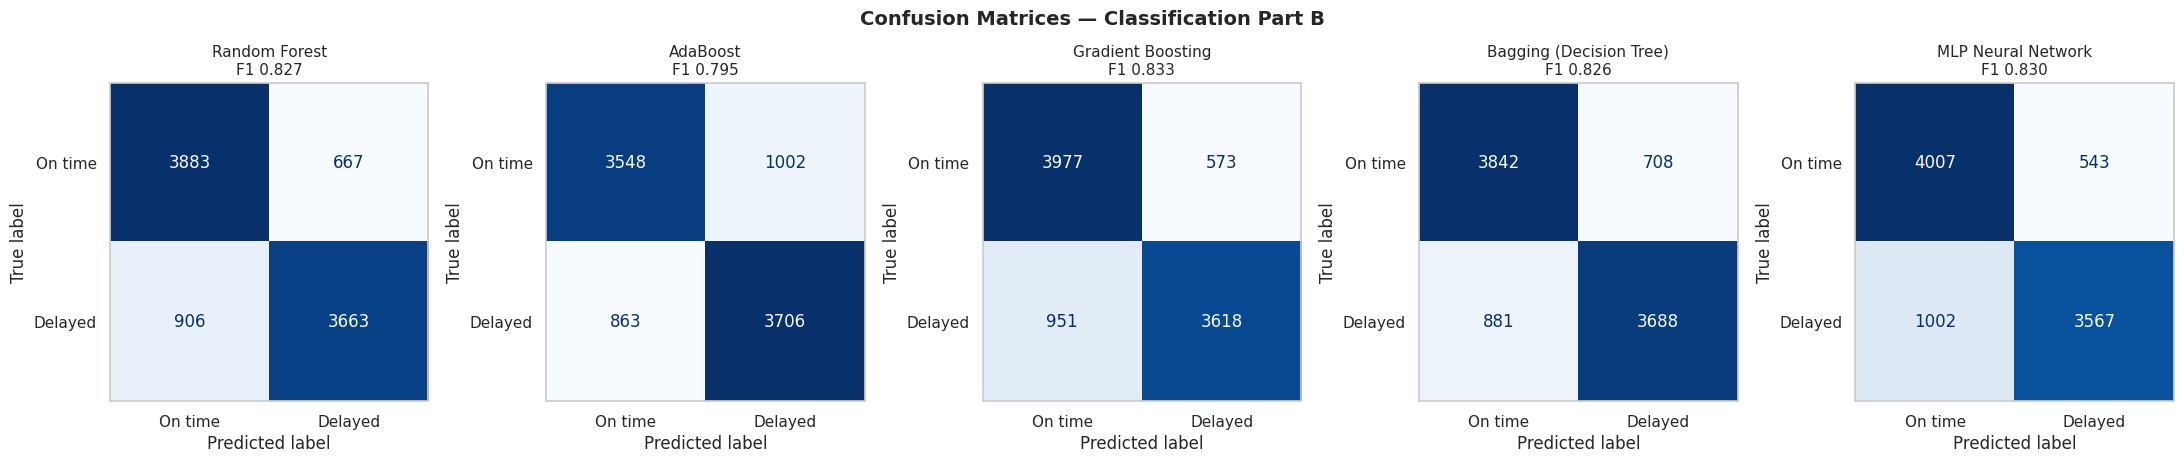

In [9]:
part_b = [m for m, r in results.items() if r['Part'] == 'B']
fig, axes = plt.subplots(1, 5, figsize=(22, 4.6))
for ax, name in zip(axes, part_b):
    ConfusionMatrixDisplay(confusion_matrix(y_test, predictions[name]),
                           display_labels=['On time', 'Delayed']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{name}\nF1 {results[name]['F1-Score (W)']:.3f}", fontsize=11)
    ax.grid(False)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
fig.suptitle('Confusion Matrices — Classification Part B', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 5. Consolidated comparison of all 10 classifiers  [Rubric A2 / Deliverable D6]
One table with every algorithm on the same test split, ranked by weighted F1 (ROC-AUC is used as the tie-breaker).

In [10]:
comparison_df = (pd.DataFrame.from_dict(results, orient='index')
                 .sort_values(['F1-Score (W)', 'ROC-AUC'], ascending=False))
comparison_df.index.name = 'Algorithm'
comparison_df.insert(0, 'Rank', range(1, len(comparison_df) + 1))

metric_cols = ['Accuracy', 'Precision (W)', 'Recall (W)', 'F1-Score (W)', 'ROC-AUC']
display(comparison_df.style
        .format({c: '{:.4f}' for c in metric_cols} | {'Train time (s)': '{:.1f}'})
        .background_gradient(cmap='Greens', subset=metric_cols)
        .set_caption('All 10 classification algorithms — same stratified 80:20 test split (n = 9,119)'))

,Rank,Part,Accuracy,Precision (W),Recall (W),F1-Score (W),ROC-AUC,Train time (s)
Algorithm,,,,,,,,
Gradient Boosting,1,B,0.8329,0.8352,0.8329,0.8326,0.9151,3.7
MLP Neural Network,2,B,0.8306,0.8340,0.8306,0.8302,0.9195,4.1
Random Forest,3,B,0.8275,0.8284,0.8275,0.8274,0.9196,1.3
Bagging (Decision Tree),4,B,0.8257,0.8262,0.8257,0.8257,0.9190,3.4
Support Vector Classifier,5,A,0.8186,0.8199,0.8186,0.8185,0.9016,1.4
Decision Tree,6,A,0.8104,0.8202,0.8104,0.8090,0.8998,0.1
K-Nearest Neighbors,7,A,0.7986,0.7992,0.7986,0.7985,0.8811,0.0
AdaBoost,8,B,0.7955,0.7957,0.7955,0.7954,0.8829,0.8
Logistic Regression,9,A,0.7857,0.7857,0.7857,0.7857,0.8689,0.4


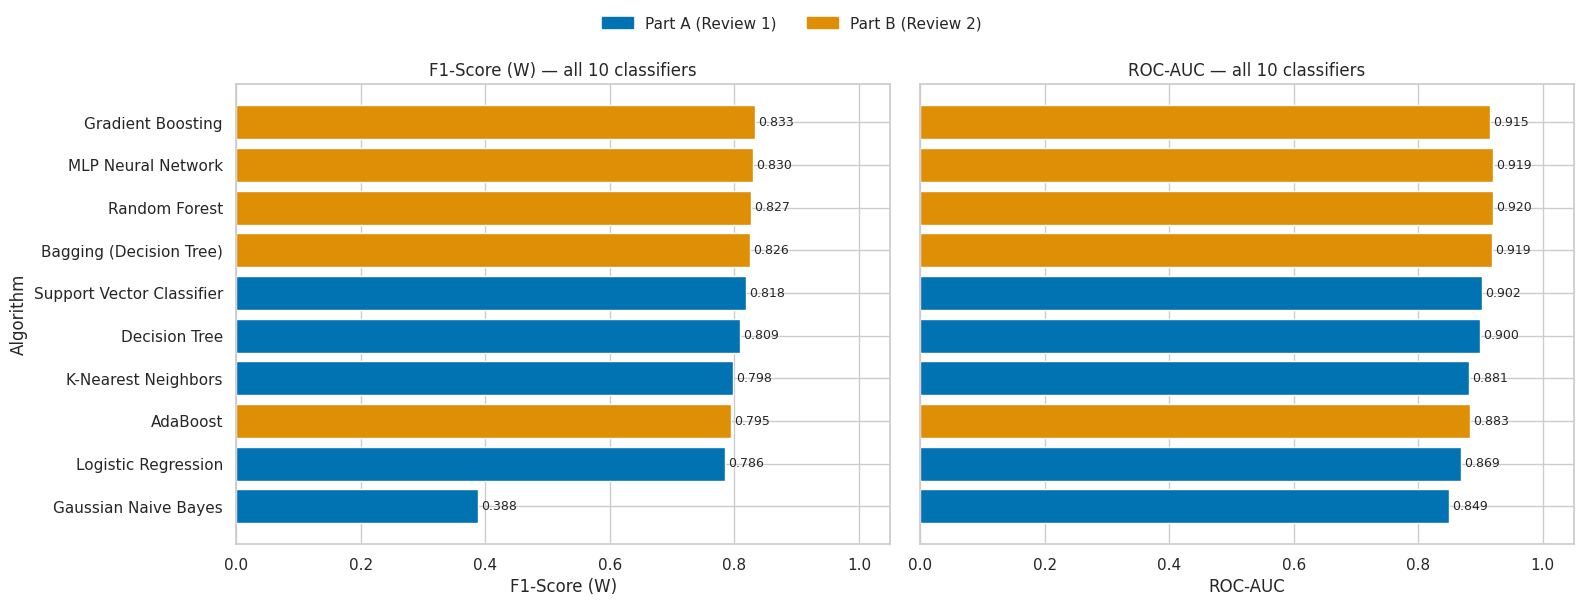

In [11]:
# Visual comparison: weighted F1 and ROC-AUC for all 10 models
plot_df = comparison_df.sort_values('F1-Score (W)')
colors = [sns.color_palette('colorblind')[0] if p == 'A' else sns.color_palette('colorblind')[1] for p in plot_df['Part']]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, metric in zip(axes, ['F1-Score (W)', 'ROC-AUC']):
    ax.barh(plot_df.index, plot_df[metric], color=colors)
    for yy, v in enumerate(plot_df[metric]):
        ax.text(v + 0.005, yy, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, 1.05)
    ax.set_title(f'{metric} — all 10 classifiers')
    ax.set_xlabel(metric)
axes[0].set_ylabel('Algorithm')
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=sns.color_palette('colorblind')[0], label='Part A (Review 1)'),
                    Patch(color=sns.color_palette('colorblind')[1], label='Part B (Review 2)')],
           loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02), frameon=False)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

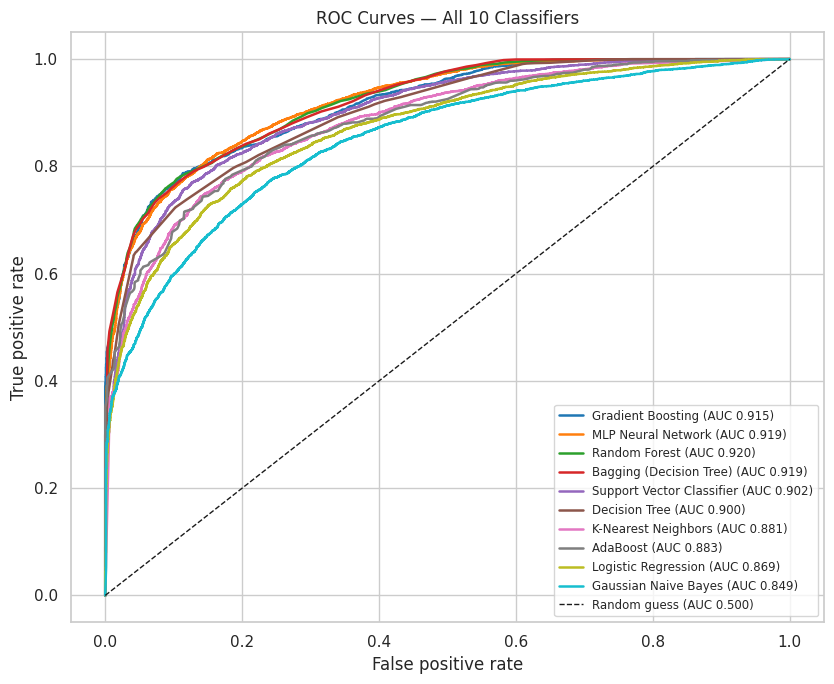

In [12]:
# ROC curves for all 10 classifiers on one chart
fig, ax = plt.subplots(figsize=(8.5, 7))
palette = sns.color_palette('tab10', 10)
for color, name in zip(palette, comparison_df.index):
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, color=color, lw=1.8, label=f"{name} (AUC {results[name]['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess (AUC 0.500)')
ax.set_title('ROC Curves — All 10 Classifiers')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.legend(loc='lower right', fontsize=8.5)
plt.tight_layout()
plt.show()

#### Observation 5: Comparing all ten classifiers
- **All four tree ensembles and the MLP beat every Part A model.** Gradient Boosting (F1 0.833), MLP (0.830), Random Forest (0.827) and Bagging (0.826) all clear the best Part A model, SVC (0.819). Their ROC-AUC is about 0.915–0.920, against 0.902 for SVC.
- **AdaBoost is the weakest ensemble (F1 0.795).** With only 50 depth-1 stumps it can capture only one feature per learner and cannot model interactions such as *traffic × weather*. It ends up below the single depth-6 Decision Tree.
- **Gaussian Naive Bayes stays last (F1 0.389).** Its ROC-AUC is still 0.849, so it ranks orders sensibly. Its hard 0/1 predictions fail because the conditional-independence assumption is broken: traffic, hour and weather are correlated, and the one-hot binary features are not Gaussian.
- The ROC curves show the same pattern. The five Part B curves (apart from AdaBoost) sit on top of each other, above the Part A curves.

#### 5.1 Five-fold cross-validation of the two best models
Guideline 7.2 requires cross-validation for at least the two best models. Stratified 5-fold CV on the **training set** checks that the test-set ranking is not luck of one particular split.

In [13]:
top2 = comparison_df.index[:2].tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name in top2:
    model = fitted_models[name]
    f1_cv = cross_val_score(model, X_train_p, y_train, cv=cv, scoring='f1_weighted', n_jobs=-1)
    auc_cv = cross_val_score(model, X_train_p, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_rows.append({'Algorithm': name, 'CV F1 mean': f1_cv.mean(), 'CV F1 std': f1_cv.std(),
                    'CV ROC-AUC mean': auc_cv.mean(), 'CV ROC-AUC std': auc_cv.std(),
                    'F1 per fold': np.round(f1_cv, 4).tolist()})
cv_df = pd.DataFrame(cv_rows).set_index('Algorithm')
display(cv_df)

,CV F1 mean,CV F1 std,CV ROC-AUC mean,CV ROC-AUC std,F1 per fold
Algorithm,,,,,
Gradient Boosting,0.8334,0.0039,0.9162,0.0025,"[0.8363, 0.8289, 0.8383, 0.8287, 0.8346]"
MLP Neural Network,0.8270,0.0037,0.9156,0.0035,"[0.8225, 0.8294, 0.8291, 0.8225, 0.8314]"


#### Observation 5.1: Cross-validation stability
- **Gradient Boosting: CV F1 = 0.833 ± 0.004, CV ROC-AUC = 0.916.** This almost exactly matches its test-set F1 of 0.833, so the result is not tied to one lucky split.
- **MLP: CV F1 = 0.827 ± 0.004.** It is slightly below its test score (0.830), which is normal random variation.
- Both standard deviations are below 0.005, so the gap between the models (about 0.006 F1) is small but consistent. Gradient Boosting is ahead in every CV summary.

---
### 6. Hyperparameter tuning  [Rubric A3]
Each Part B algorithm has a tuning requirement in the guidelines. `GridSearchCV` (3-fold stratified CV, scored on weighted F1) is run on a fixed 10,000-row slice of the training set to keep the search time reasonable. The best setting is then **refitted on the full training set** and scored on the untouched test set, so the baseline and tuned numbers are directly comparable.

| Algorithm | Parameters searched (guideline requirement) |
|---|---|
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf` |
| AdaBoost | `n_estimators`, `learning_rate` |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth` |
| Bagging | `n_estimators`, `max_samples` |
| MLP | `hidden_layer_sizes`, `activation`, `alpha` |

In [14]:
tune_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train_p), 10000, replace=False)
X_tune, y_tune = X_train_p[tune_idx], y_train.iloc[tune_idx]
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
                      {'n_estimators': [100, 300], 'max_depth': [None, 20], 'min_samples_leaf': [1, 3]}),
    'AdaBoost': (AdaBoostClassifier(random_state=RANDOM_STATE),
                 {'n_estimators': [100, 300, 500], 'learning_rate': [0.1, 0.5, 1.0]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {'n_estimators': [200, 400], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]}),
    'Bagging (Decision Tree)': (BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                                                  random_state=RANDOM_STATE, n_jobs=-1),
                                {'n_estimators': [50, 150], 'max_samples': [0.7, 1.0]}),
    'MLP Neural Network': (MLPClassifier(max_iter=400, early_stopping=True, random_state=RANDOM_STATE),
                           {'hidden_layer_sizes': [(64,), (128, 64), (64, 32, 16)],
                            'activation': ['relu', 'tanh'], 'alpha': [1e-4, 1e-3]}),
}

tuned_models, tuning_rows = {}, []
for name, (estimator, grid) in search_space.items():
    start = time.time()
    gs = GridSearchCV(estimator, grid, cv=cv3, scoring='f1_weighted', n_jobs=-1)
    gs.fit(X_tune, y_tune)
    best = gs.best_estimator_.fit(X_train_p, y_train)          # refit best setting on full train set
    y_pred = best.predict(X_test_p)
    y_score = best.predict_proba(X_test_p)[:, 1]
    tuned_models[name] = best
    tuning_rows.append({
        'Algorithm': name, 'Best parameters': gs.best_params_,
        'Baseline F1': results[name]['F1-Score (W)'], 'Tuned F1': f1_score(y_test, y_pred, average='weighted'),
        'Baseline ROC-AUC': results[name]['ROC-AUC'], 'Tuned ROC-AUC': roc_auc_score(y_test, y_score),
        'Tuned Accuracy': accuracy_score(y_test, y_pred), 'Search time (s)': time.time() - start})
    print(f'{name:<25} best {gs.best_params_}  ({time.time() - start:.0f}s)')

tuning_df = pd.DataFrame(tuning_rows).set_index('Algorithm')
tuning_df['F1 change'] = tuning_df['Tuned F1'] - tuning_df['Baseline F1']
tuning_df['ROC-AUC change'] = tuning_df['Tuned ROC-AUC'] - tuning_df['Baseline ROC-AUC']
display(tuning_df.sort_values('Tuned F1', ascending=False))

Random Forest             best {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 300}  (18s)


AdaBoost                  best {'learning_rate': 0.5, 'n_estimators': 300}  (24s)


Gradient Boosting         best {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}  (50s)


Bagging (Decision Tree)   best {'max_samples': 0.7, 'n_estimators': 150}  (16s)


MLP Neural Network        best {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (128, 64)}  (24s)


,Best parameters,Baseline F1,Tuned F1,Baseline ROC-AUC,Tuned ROC-AUC,Tuned Accuracy,Search time (s),F1 change,ROC-AUC change
Algorithm,,,,,,,,,
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.8326,0.8439,0.9151,0.9290,0.8443,50.1022,0.0113,0.0139
Random Forest,"{'max_depth': None, 'min_samples_leaf': 3, 'n_...",0.8274,0.8391,0.9196,0.9256,0.8393,18.4220,0.0117,0.0060
MLP Neural Network,"{'activation': 'tanh', 'alpha': 0.001, 'hidden...",0.8302,0.8385,0.9195,0.9276,0.8386,24.1060,0.0083,0.0081
Bagging (Decision Tree),"{'max_samples': 0.7, 'n_estimators': 150}",0.8257,0.8307,0.9190,0.9229,0.8308,15.8278,0.0050,0.0039
AdaBoost,"{'learning_rate': 0.5, 'n_estimators': 300}",0.7954,0.7985,0.8829,0.8851,0.7986,23.9705,0.0031,0.0022


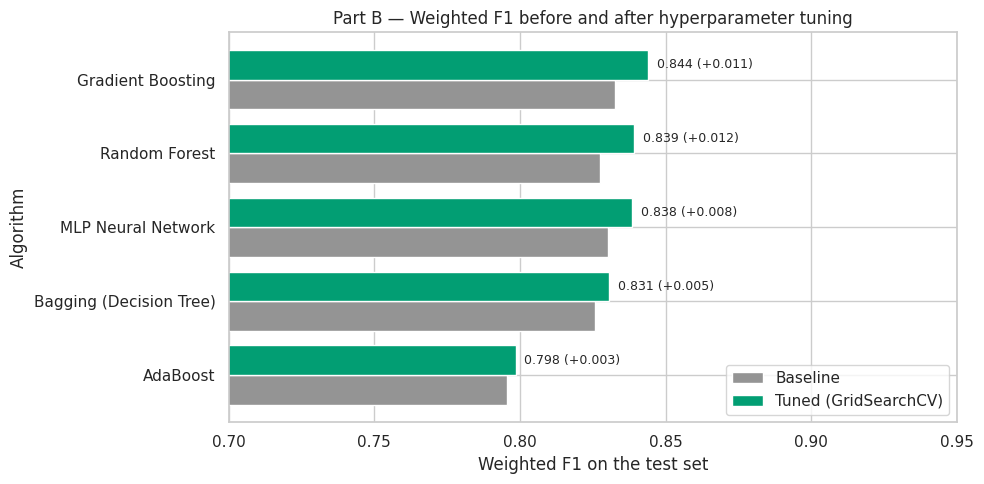

In [15]:
# Baseline vs tuned weighted F1 for every Part B model
plot_t = tuning_df.sort_values('Tuned F1')
yy = np.arange(len(plot_t))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(yy - 0.2, plot_t['Baseline F1'], height=0.4, label='Baseline', color=sns.color_palette('colorblind')[7])
ax.barh(yy + 0.2, plot_t['Tuned F1'], height=0.4, label='Tuned (GridSearchCV)', color=sns.color_palette('colorblind')[2])
for i, (b, t) in enumerate(zip(plot_t['Baseline F1'], plot_t['Tuned F1'])):
    ax.text(t + 0.003, i + 0.2, f'{t:.3f} ({t - b:+.3f})', va='center', fontsize=9)
ax.set_yticks(yy, plot_t.index)
ax.set_xlim(0.7, 0.95)
ax.set_title('Part B — Weighted F1 before and after hyperparameter tuning')
ax.set_xlabel('Weighted F1 on the test set')
ax.set_ylabel('Algorithm')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

#### Observation 6: Effect of hyperparameter tuning
- **Every Part B model improved after tuning.** The biggest gains were for Random Forest (+0.012 F1) and Gradient Boosting (+0.011 F1, +0.014 ROC-AUC).
- **Gradient Boosting** chose `learning_rate=0.05, max_depth=5, n_estimators=200`. Deeper trees let each boosting step model 5-way feature interactions, and the smaller learning rate stops those deeper trees from overfitting.
- **Random Forest** chose `min_samples_leaf=3` with 300 trees. Slightly larger leaves smooth out noisy single-order leaves, and more trees lower the variance.
- **MLP** preferred a deeper `(128, 64)` network with `tanh` and stronger L2 regularisation (`alpha=0.001`).
- **AdaBoost** improved only slightly (+0.003) even with 300 learners. This confirms its limit is the depth-1 weak learner, not the number of rounds.

---
### 7. Final model selection  [Rubric A3]
The final model is the tuned model with the highest weighted F1 on the test set (ROC-AUC as tie-breaker). Below we look at it in detail: its classification report, confusion matrix, ROC curve and which features drive its decisions (permutation importance, which works for any model type).

In [16]:
final_name = tuning_df.sort_values(['Tuned F1', 'Tuned ROC-AUC'], ascending=False).index[0]
final_model = tuned_models[final_name]
final_pred = final_model.predict(X_test_p)
final_score = final_model.predict_proba(X_test_p)[:, 1]

print(f'FINAL MODEL: {final_name}')
print(f'Parameters : {tuning_df.loc[final_name, "Best parameters"]}\n')
print(classification_report(y_test, final_pred, target_names=['On time (0)', 'Delayed (1)'], digits=4))

before_after = pd.DataFrame({
    'Baseline': [results[final_name][m] for m in metric_cols],
    'Tuned': [accuracy_score(y_test, final_pred),
              precision_score(y_test, final_pred, average='weighted'),
              recall_score(y_test, final_pred, average='weighted'),
              f1_score(y_test, final_pred, average='weighted'),
              roc_auc_score(y_test, final_score)]}, index=metric_cols)
before_after['Improvement'] = before_after['Tuned'] - before_after['Baseline']
display(before_after)

FINAL MODEL: Gradient Boosting
Parameters : {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}

              precision    recall  f1-score   support

 On time (0)     0.8139    0.8919    0.8511      4550
 Delayed (1)     0.8810    0.7969    0.8368      4569

    accuracy                         0.8443      9119
   macro avg     0.8474    0.8444    0.8440      9119
weighted avg     0.8475    0.8443    0.8439      9119



,Baseline,Tuned,Improvement
Accuracy,0.8329,0.8443,0.0114
Precision (W),0.8352,0.8475,0.0123
Recall (W),0.8329,0.8443,0.0114
F1-Score (W),0.8326,0.8439,0.0113
ROC-AUC,0.9151,0.9290,0.0139


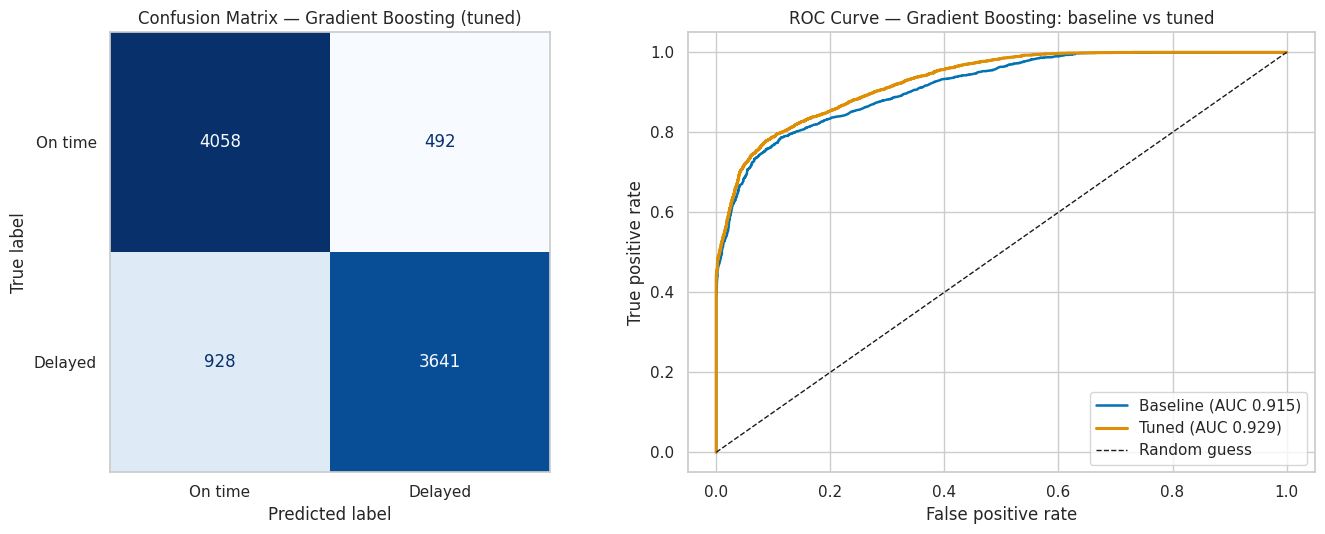

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred), display_labels=['On time', 'Delayed']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — {final_name} (tuned)')
axes[0].grid(False)
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')

fpr_b, tpr_b, _ = roc_curve(y_test, scores[final_name])
fpr_t, tpr_t, _ = roc_curve(y_test, final_score)
axes[1].plot(fpr_b, tpr_b, lw=1.8, label=f"Baseline (AUC {results[final_name]['ROC-AUC']:.3f})")
axes[1].plot(fpr_t, tpr_t, lw=2.2, label=f'Tuned (AUC {roc_auc_score(y_test, final_score):.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
axes[1].set_title(f'ROC Curve — {final_name}: baseline vs tuned')
axes[1].set_xlabel('False positive rate')
axes[1].set_ylabel('True positive rate')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

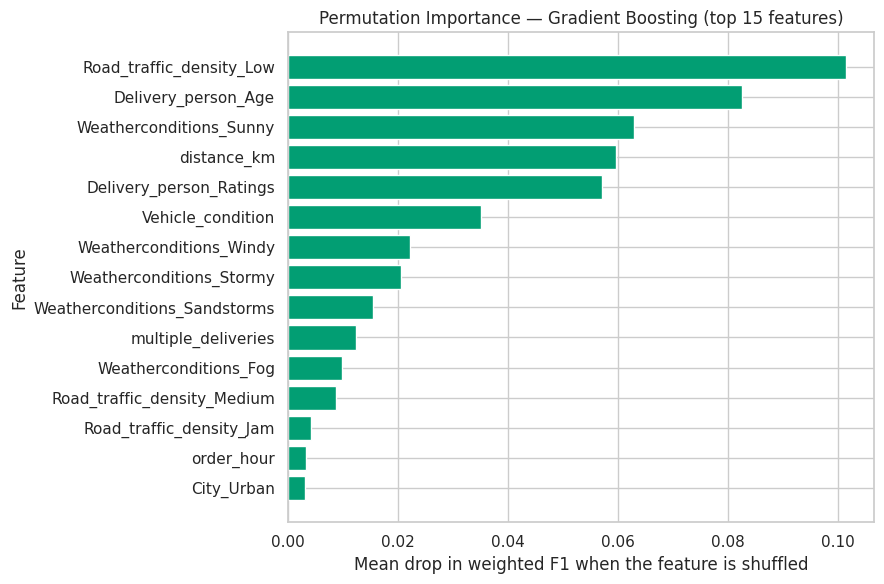

In [18]:
# Permutation importance: drop in weighted F1 when one feature is randomly shuffled (on a 3,000-row test sample)
perm_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test_p), 3000, replace=False)
perm = permutation_importance(final_model, X_test_p[perm_idx], y_test.iloc[perm_idx],
                              scoring='f1_weighted', n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=feature_names).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(perm_s.index, perm_s.values, color=sns.color_palette('colorblind')[2])
ax.set_title(f'Permutation Importance — {final_name} (top 15 features)')
ax.set_xlabel('Mean drop in weighted F1 when the feature is shuffled')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# Save the final model and its preprocessor for reuse by the Streamlit GUI (app/app.py)
import sklearn
MODELS_DIR = '../models' if os.path.basename(os.getcwd()) == 'notebooks' else 'models'
os.makedirs(MODELS_DIR, exist_ok=True)
joblib.dump({'preprocessor': preprocessor, 'model': final_model, 'features': NUMERICAL_COLS + CATEGORICAL_COLS,
             'feature_names': feature_names, 'name': f'{final_name} Classifier (tuned)',
             'sklearn_version': sklearn.__version__, 'n_train': len(X_train), 'n_test': len(X_test),
             'metrics': {'Accuracy': accuracy_score(y_test, final_pred),
                         'Precision': precision_score(y_test, final_pred, average='weighted'),
                         'Recall': recall_score(y_test, final_pred, average='weighted'),
                         'F1': f1_score(y_test, final_pred, average='weighted'),
                         'ROC-AUC': roc_auc_score(y_test, final_score)}},
            os.path.join(MODELS_DIR, 'best_classifier.pkl'), compress=3)
print(f'Saved {MODELS_DIR}/best_classifier.pkl')

---
## 8. Observations: which model performs best, and why

### Best model: tuned Gradient Boosting Classifier
`GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=5)`

| Metric (test set, n = 9,119) | Baseline GBM | Tuned GBM | Best Part A model (SVC) |
|---|---|---|---|
| Accuracy | 0.8329 | **0.8443** | 0.8186 |
| Weighted F1 | 0.8326 | **0.8439** | 0.8185 |
| ROC-AUC | 0.9151 | **0.9290** | 0.9016 |
| 5-fold CV F1 | 0.8334 ± 0.0039 | — | — |

It ranks **first on every metric** among all ten algorithms, both before and after tuning. The cross-validation confirms the result is stable.

### Why Gradient Boosting wins on this dataset
1. **Delays are driven by feature interactions, not straight-line effects.** In the data, **100%** of festival orders and **100%** of trips with 2 or more multiple deliveries are delayed. Delay rates also range from **25% in Low traffic to 70% in Jam traffic**, and weather shifts them further. Such threshold and interaction patterns cannot be drawn with one straight line, which is why Logistic Regression stops at F1 0.786. Depth-5 trees capture them directly as splits.
2. **Boosting reduces bias; bagging mainly reduces variance.** Random Forest and Bagging average many independent deep trees, which lowers variance but not bias. Gradient Boosting adds trees one after another, each fitting the errors the current ensemble still makes. The hard borderline orders (around 25 minutes) therefore get extra attention, which gives the extra ~0.5 percentage points of F1 and ~0.3–0.6 points of ROC-AUC over the bagging-based models.
3. **It works well with mixed feature types.** Trees need no distance metric, so the 10 scaled continuous features and 13 one-hot dummies are handled equally well. KNN and SVC depend on distances in this mixed space, and Naive Bayes assumes Gaussian, independent features.
4. **The tuning result makes sense.** A lower learning rate (0.05) with deeper trees (depth 5) is the classic GBM trade-off: each tree can model richer interactions, and the smaller steps keep the ensemble from memorising noise. This is why tuning improved every metric (Accuracy +1.14 points, F1 +1.13, ROC-AUC +1.39).
5. **The permutation importance matches the domain.** Shuffling **`Road_traffic_density_Low`** hurts the tuned model most (−0.10 F1), followed by **rider age, sunny weather, distance and rider rating**. These are the same drivers found in the Review 1 EDA, so the model is using real signals and not data artefacts.

### Close runners-up and trade-offs
- **MLP (tuned F1 0.839, ROC-AUC 0.928)** is almost as good, but it is a black box, depends on scaling and random initialisation, and is harder to explain in a viva or to an operations team.
- **Random Forest (tuned F1 0.839)** trains in parallel and is more robust with default settings. If training time or simplicity mattered more than the last 0.5% of F1, it would be a good alternative.
- **Error profile of the final model.** Precision for *Delayed* is 0.881 and recall is 0.797 (928 missed delays against 492 false alarms). The model is cautious about flagging delays. If missing a delay costs the business more than a false alarm, lowering the decision threshold below 0.5 would raise recall at the cost of precision.

### Conclusion
**The tuned Gradient Boosting Classifier is selected as the final Review 2 classification model.** It gives the highest Accuracy (84.4%), weighted F1 (0.844) and ROC-AUC (0.929) of all ten algorithms, its lead is confirmed by 5-fold cross-validation, and its behaviour matches the delivery-logistics findings from EDA. It is saved to `models/best_classifier.pkl` together with the fitted preprocessor for the optional GUI bonus.

---
## 9. Interactive GUI (bonus)
The saved classifier, together with the regression model saved in `regression.ipynb`, powers **TrackBite**, a Streamlit food-order tracker in `app/app.py`. For any order it shows the predicted delivery time (regressor), the probability that the order breaches the 25-minute SLA (this classifier), the live delivery stages and a what-if breakdown of which conditions add the most minutes.

Run it from the repository root with `streamlit run app/app.py` (see README.md).